# Sea ice segmentation using a custom IFT pipeline
- Check alignment of the land mask
- Flag scenes without sufficient ocean coverage
- Use erosion expansion initially with distance split for second pass.

In [2]:
using Pkg; Pkg.activate("../scripts/ift-eddies/")
using IceFloeTracker
using Images
using CairoMakie


  Activating project at `~/Documents/research/manuscripts/ift_eddy_detection/ift_eddy_detection/scripts/ift-eddies`


In [4]:
landmask = load("../data/landmask.tiff") |> r -> Gray.(r) .> 0;
tc_img = load("../data/truecolor/modis.truecolor.20070708.1040.aqua.png");

In [23]:
function unsharp_mask_fir(
    img::AbstractArray{<:Union{AbstractRGB,TransparentRGB,AbstractGray}},
    radius::Real=3,
    amount::Real=0.5,
    threshold::Real=0.01,
)
    image_float = float64.(img)
    image_smoothed = imfilter(image_float, Kernel.gaussian(radius), Algorithm.FIR())

    cv_image = channelview(image_float)
    cv_smooth = channelview(image_smoothed)
    diff = cv_image .- cv_smooth
    cv_sharp = cv_image .+ diff .* amount
    clamp!(cv_sharp, 0, 1)

    # Convert back into an image of the original type
    sharpened_image = colorview(base_colorant_type(eltype(img)), cv_sharp)
    sharpened_image = convert.(eltype(img), sharpened_image)

    # Optionally use only where sharpening is larger than threshold
    diff_magnitude = if length(size(diff)) > 2
        dropdims(sqrt.(sum(diff .^ 2; dims=1)); dims=1)
    else
        abs.(diff)
    end

    threshold > 0 &&
        (sharpened_image[diff_magnitude .< threshold] .= img[diff_magnitude .< threshold])
    return sharpened_image
end


unsharp_mask_fir (generic function with 4 methods)

In [24]:
import IceFloeTracker: nonlinear_diffusion

diffusion_algorithm = PeronaMalikDiffusion(; λ=0.1, K=0.1, niters=7, g="exponential")
adapthisteq_params = (nbins=256, rblocks=4, cblocks=4, clip=1)
unsharp_mask_params = (radius=50, amount=0.3, threshold=0.01)

tiles = get_tiles(tc_img; rblocks=8, cblocks=4)
proc_img = apply_landmask(Gray.(tc_img), landmask)
proc_img .= nonlinear_diffusion(proc_img, tiles, diffusion_algorithm)
adjust_histogram!(
    proc_img,
    ContrastLimitedAdaptiveHistogramEqualization(;
        nbins=adapthisteq_params.nbins,
        rblocks=adapthisteq_params.rblocks,
        cblocks=adapthisteq_params.cblocks,
        clip=adapthisteq_params.clip,
    ),
)

proc_img .= unsharp_mask_fir(
    proc_img,
    unsharp_mask_params.radius,
    unsharp_mask_params.amount,
    unsharp_mask_params.threshold,
)

apply_landmask!(proc_img, landmask)

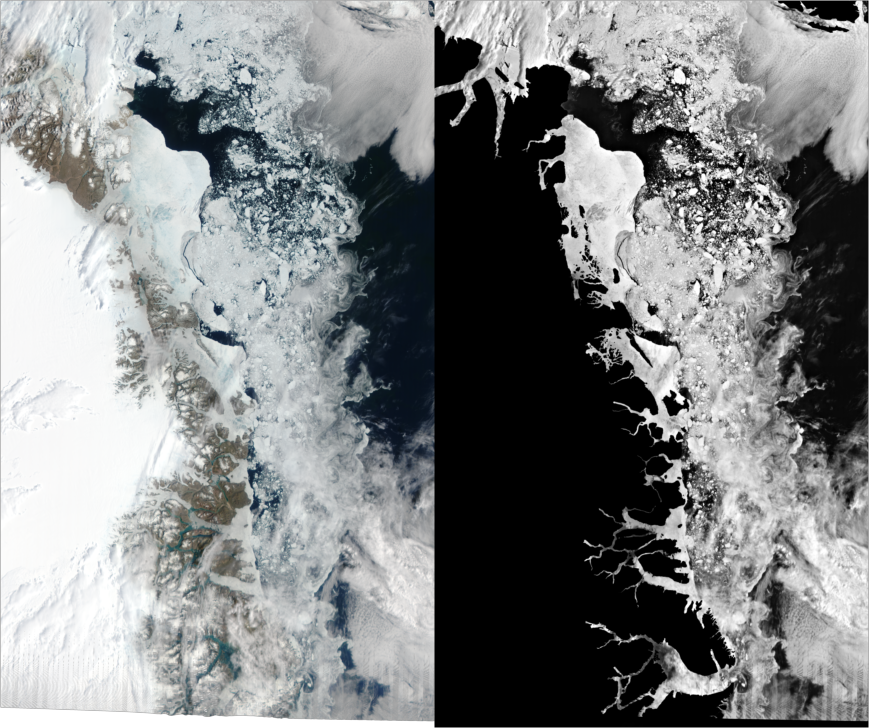

In [25]:
mosaicview(tc_img, proc_img, nrow=1)

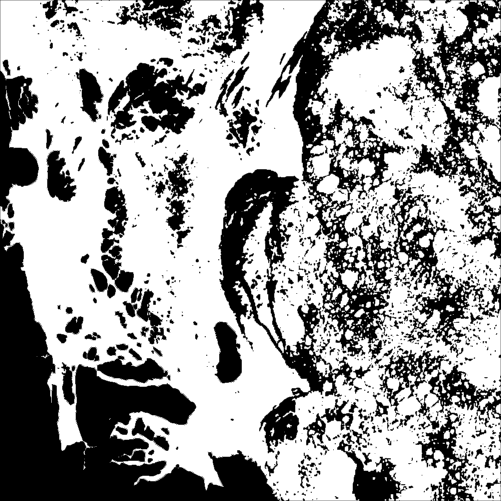

In [28]:
binarized_img = apply_landmask(
    binarize(proc_img, AdaptiveThreshold(; window_size=200, percentage=0)),
    landmask
)
binarized_img[1500:2500, 1000:2000]

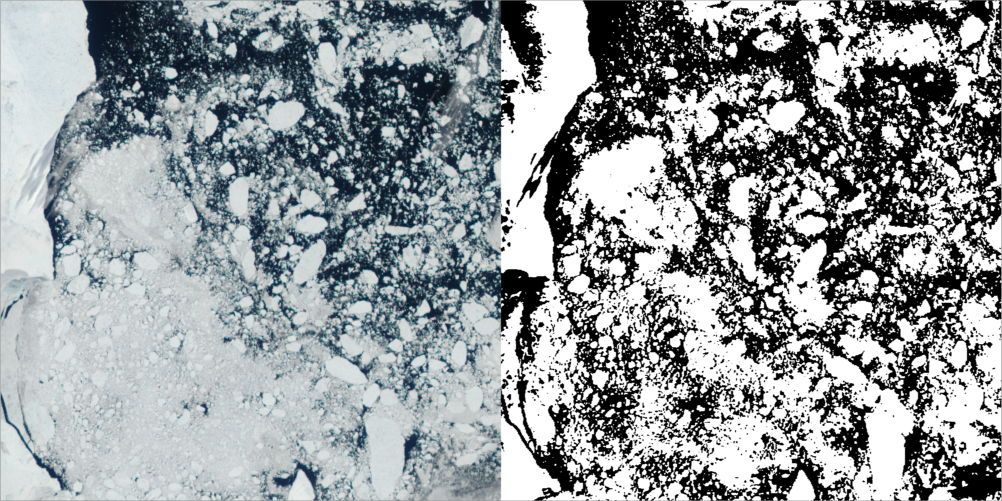

In [30]:
z = (1300:2300, 1500:2500)
mosaicview(tc_img[z...], binarized_img[z...], nrow=1)

In [36]:
test_view = view_seg_random(
    SegmentedImage(
        tc_img[z...],
        dist_morph_split(binarized_img .> 0)
        )
    )

LoadError: Image and index map must have the same axes, got (Base.OneTo(1001), Base.OneTo(1001)) and (Base.OneTo(5816), Base.OneTo(3472))